# 02 · Monitor a model in production

A model that explains well on the training data can still go wrong in production, often because the data feeding it changes. This notebook puts the models from [notebook 01](01-explain-a-model.ipynb) "into production" and watches them with Kaimei:

1. two ways predictions reach Kaimei: Kaimei scores a passenger itself, or your own service logs what it scored;
2. two weeks of normal traffic, with the logistic regression running in **shadow** next to the forest;
3. a drift check that comes back clean;
4. an incident: a new data feed starts sending fares in pence instead of pounds. Kaimei's drift analysis flags it, and an explanation shows the damage.

**Needs** notebook 01's models. **Uses** about 1,140 logged predictions, 1 explanation and 2 analyses of a free Kaimei plan.

**Before you start:** `pip install -r requirements.txt` from the repository root, and copy `.env.example` to `.env` with your Kaimei API key (dashboard → **API keys**). The notebook asks for the key if it can't find one.

> **Running on Google Colab or without a clone?** Install this example first; the data downloads by itself:
> ```python
> %pip install -q "titanic-kaimei-example[xgboost,serve] @ git+https://github.com/KaimeiAI/titanic-kaimei-example"
> ```

## 1. Connect

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kaimei import NotFoundError
from kaimei.tabular import explanation_summary, plot_explanation, plot_insight
from titanic_kaimei import encode, load, to_row, to_rows
from titanic_kaimei.models import make_forest, make_logistic, split
from titanic_kaimei.workspace import FOREST, LOGISTIC, connect, dashboard_url, run_analysis

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 3)

client = connect()
try:
    forest_model = client.models.retrieve(FOREST)
except NotFoundError:
    raise RuntimeError("Run notebook 01 first: it uploads the models this notebook monitors.") from None

Connected to Kaimei at https://api.kaimei.ai (workspace: Kaimei Workspace)


## 2. Two ways predictions reach Kaimei

**Kaimei scores it.** For a model Kaimei runs itself, `client.models.predict` returns the prediction and, by default, logs it. That's handy for what-ifs, like two passengers who were never on the manifest:

In [2]:
jack = {"Pclass": 3, "Sex": "male", "Age": 20, "SibSp": 0, "Parch": 0, "Fare": 7.75, "Embarked": "Southampton",
        "FamSize": 1, "IsAlone": True, "Title": "Mr"}
rose = {"Pclass": 1, "Sex": "female", "Age": 17, "SibSp": 0, "Parch": 1, "Fare": 151.55, "Embarked": "Southampton",
        "FamSize": 2, "IsAlone": False, "Title": "Miss"}
for name, guest in [("Jack", jack), ("Rose", rose)]:
    answer = client.models.predict(FOREST, input=guest, log=False).output  # log=False: a what-if, not traffic
    print(f"{name}: {answer['label']} (P(survived) = {answer['value']:.0%})")

Jack: died (P(survived) = 12%)


Rose: survived (P(survived) = 93%)


**Your service scores it.** Most teams already serve models with their own stack and only need Kaimei to see what happened. Log each prediction with `client.predictions.create`, or up to 1,000 at a time with `create_batch`. Each item carries:
- the input,
- the output your model produced,
- optionally a timestamp, your own prediction id, and metadata.

Here, Kaggle's 418 test passengers stand in for two weeks of traffic. The forest scores them in this notebook: it's retrained exactly as notebook 01 trained it (same data, split and seed), so it's the same model. The logistic regression scores the same passengers in **shadow mode**: logged, never acted on, so you can compare a candidate model with the live one on real traffic.

In [3]:
titanic = load(1)
X, y = encode(titanic.passengers), titanic.survived
X_train, _, y_train, _ = split(X, y)
forest = make_forest().fit(X_train, y_train)        # the model uploaded in notebook 01
logistic = make_logistic().fit(X_train, y_train)    # its shadow
SURVIVED = list(forest.classes_).index("survived")


def log_traffic(model_slug, model, passengers, *, start, days, batch):
    # Score the passengers with our own copy of the model and log what it said, spread over `days`.
    p = model.predict_proba(encode(passengers))[:, SURVIVED]
    items = [
        {
            "input": row,
            "output": {"label": "survived" if q >= 0.5 else "died", "value": float(q),
                       "probability": float(max(q, 1 - q))},
            "timestamp": (start + timedelta(days=days) * i / len(passengers)).isoformat(),
            "metadata": {"batch": batch},
        }
        for i, (row, q) in enumerate(zip(to_rows(passengers), p))
    ]
    logged = client.predictions.create_batch(model=model_slug, items=items)
    return p, logged


now = datetime.now(timezone.utc)
p_forest, _ = log_traffic(FOREST, forest, titanic.new_passengers, start=now - timedelta(days=16), days=14, batch="normal")
p_shadow, _ = log_traffic(LOGISTIC, logistic, titanic.new_passengers, start=now - timedelta(days=16), days=14, batch="normal")

disagree = (p_forest >= 0.5) != (p_shadow >= 0.5)
print(f"Logged {len(p_forest)} passengers to each model. The forest says {np.mean(p_forest >= 0.5):.0%} survive, "
      f"the shadow model {np.mean(p_shadow >= 0.5):.0%}; they disagree on {disagree.sum()} passengers.")

Logged 418 passengers to each model. The forest says 39% survive, the shadow model 37%; they disagree on 28 passengers.


Where the two models disagree is where a switch would change real decisions. Those passengers are worth explaining with both models, as notebook 01 did for Mr Braund:

In [4]:
disagreements = titanic.new_passengers[disagree].assign(forest=p_forest[disagree], shadow=p_shadow[disagree])
disagreements.groupby(["Pclass", "Sex"]).size().rename("passengers").to_frame()

passengers
Pclass Sex               
1      male             9
3      female           8
       male            11

## 3. A drift check

Drift compares the latest logged inputs, up to 500, with the reference passengers uploaded with the model. For each input it computes a **population stability index** (PSI): below 0.1 is stable, above 0.25 is a significant shift. It does the same for the model's own predictions. A `drift` analysis runs just that check.

Recent inputs match the reference population (max PSI 0.03).


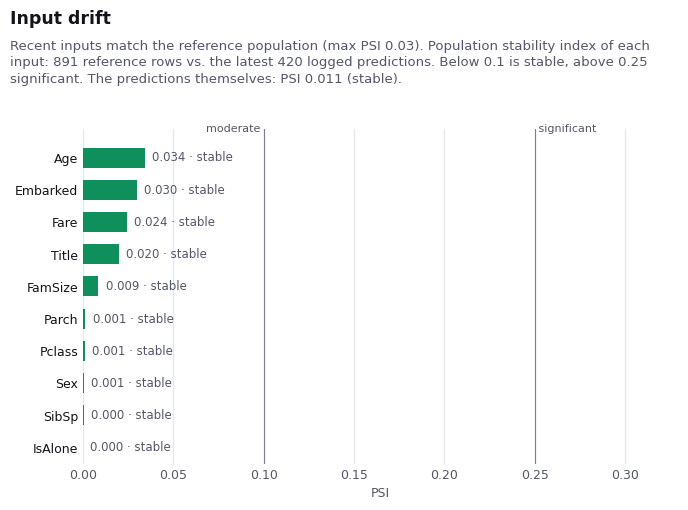

In [5]:
insights = run_analysis(client, FOREST, "drift")
print(insights["drift"].summary)
plot_insight(insights["drift"], model=forest_model)
plt.show()

Kaggle's test passengers look like its training passengers, as they should.

## 4. An incident: fares in pence

Two days ago a new booking feed went live. Nobody noticed that it sends fares in **pence** rather than pounds, so a £7.25 ticket arrives as 725. Nothing errors: the model happily scores 725 as a very expensive ticket.

Here, 300 passengers arrive through that feed:

In [6]:
feed = titanic.new_passengers.sample(300, random_state=1)
broken = feed.assign(Fare=(feed["Fare"] * 100).round(2))

p_broken, logged = log_traffic(FOREST, forest, broken, start=now - timedelta(days=2), days=2, batch="new feed")
p_correct = forest.predict_proba(encode(feed))[:, SURVIVED]
print(f"Average P(survived) for these 300 passengers: {p_correct.mean():.0%} with correct fares, "
      f"{p_broken.mean():.0%} as logged.")

Average P(survived) for these 300 passengers: 41% with correct fares, 51% as logged.


The same drift check now:

high | Recent traffic has significant drift (PSI 1.55). Shifted inputs: `Fare`.


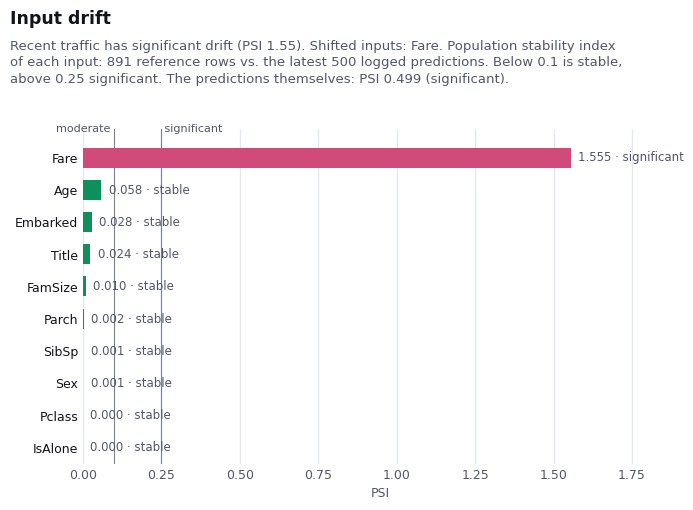

In [7]:
insights = run_analysis(client, FOREST, "drift")
print(insights["drift"].severity, "|", insights["drift"].summary)
plot_insight(insights["drift"], model=forest_model)
plt.show()

Kaimei flags `Fare` with a significant shift and marks the insight **high** severity. The project page lists it under *Needs attention*. The **predictions** have drifted as well, which is the part that hurts: the model is now telling a different story about the same kind of passenger.

### Diagnose one prediction

Pick a third-class passenger from the new feed and explain the prediction that was logged for them. `prediction_id` links the explanation to that logged prediction, so it shows up on the prediction's record in the dashboard:

The model predicts died: P(survived) = 35.3%, against 41.1% on average over the reference data. Pulling P(survived) down: Sex = male (−11.7 pts), Title = Mr (−7.1 pts), Pclass = 3 (−4.0 pts). Pushing P(survived) up: Fare = 775 GBP (+14.3 pts), FamSize = 1 (+1.4 pts), SibSp = 0 (+1.2 pts).


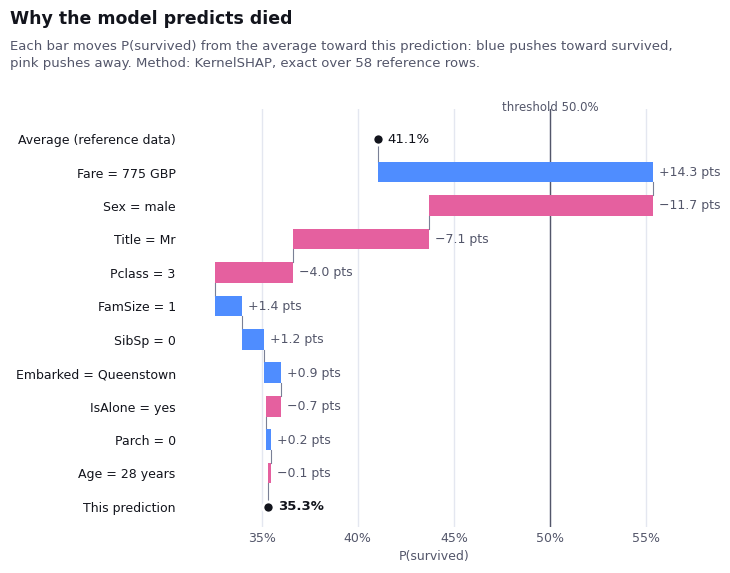

With the fare in pounds (£7.75): P(survived) = 9.4%


In [8]:
third_class = next(item for item in logged.data if item["input"]["Pclass"] == 3)
explanation = client.explanations.create(
    model=FOREST, input=third_class["input"], prediction_id=third_class["id"], method="shap", options={"seed": 0}
)
print(explanation_summary(explanation, model=forest_model))
plot_explanation(explanation, model=forest_model)
plt.show()

fixed = {**third_class["input"], "Fare": round(third_class["input"]["Fare"] / 100, 2)}
fixed_answer = client.models.predict(FOREST, input=fixed, log=False).output
print(f"With the fare in pounds (£{fixed['Fare']}): P(survived) = {fixed_answer['value']:.1%}")

The explanation points straight at the bug: a third-class passenger whose "fare" is the largest push toward survival. With the fare converted back to pounds, the prediction drops.

In a real system you would now:
- fix the feed;
- re-score the passengers it affected;
- keep the drift check on a schedule. `client.analyses.create(model=..., type="drift")` can run from a cron job or your pipeline after each batch.

On the dashboard, the forest's **Insights** tab shows the drift card in red, and **Predictions** lists every logged prediction.

**Next:** [03 · Improve and version](03-improve-and-version.ipynb) acts on what notebook 01 found and ships a better version of the forest.

In [9]:
print(dashboard_url(f"models/{FOREST}/insights"))
print(dashboard_url(f"models/{FOREST}/predictions"))
print(dashboard_url("projects/titanic"))

https://dashboard.kaimei.ai/models/titanic-forest/insights
https://dashboard.kaimei.ai/models/titanic-forest/predictions
https://dashboard.kaimei.ai/projects/titanic
